<a href="https://colab.research.google.com/github/Anandthrissur2004/Round_Robin/blob/main/Anand_B_Krishna_Roundrobin.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


Time Quantum: 2 ms

Execution Sequence:
P1 (0-2) -> P2 (2-4) -> P3 (4-6) -> P1 (6-8) -> P4 (8-10) -> P2 (10-11) -> P3 (11-13) -> P1 (13-14)

Process Performance:
Process  Completion Time  Turnaround Time  Waiting Time  Response Time
     P1               14               14             9              0
     P2               11               10             7              1
     P3               13               11             7              2
     P4               10                7             5              5

Average Turnaround Time: 10.5 ms
Average Waiting Time: 7.0 ms
Context Switches: 7


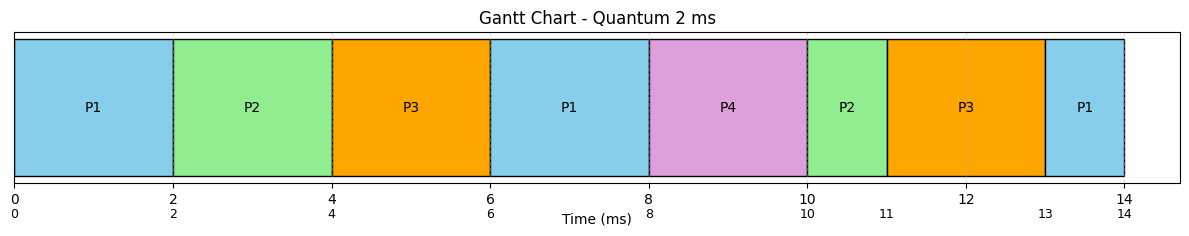


Time Quantum: 3 ms

Execution Sequence:
P1 (0-3) -> P2 (3-6) -> P3 (6-9) -> P4 (9-11) -> P1 (11-13) -> P3 (13-14)

Process Performance:
Process  Completion Time  Turnaround Time  Waiting Time  Response Time
     P1               13               13             8              0
     P2                6                5             2              2
     P3               14               12             8              4
     P4               11                8             6              6

Average Turnaround Time: 9.5 ms
Average Waiting Time: 6.0 ms
Context Switches: 5


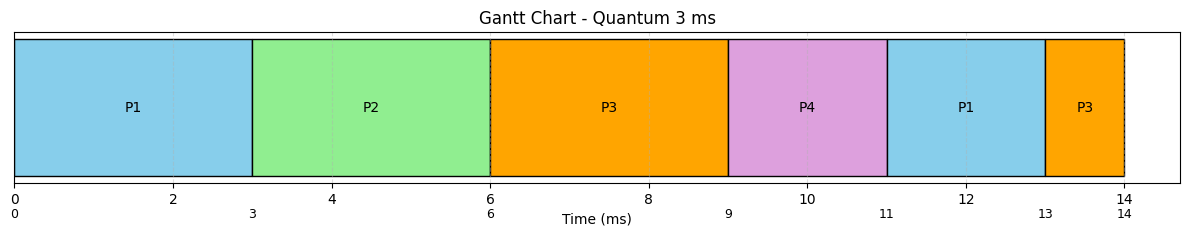


COMPARISON TABLE
 Quantum (ms)  Average Turnaround (ms)  Average Waiting (ms)  Context Switches
            2                     10.5                   7.0                 7
            3                      9.5                   6.0                 5


In [2]:

import pandas as pd
import matplotlib.pyplot as plt
from collections import deque

# Activity 1: Municipal Sustainability Services
processes = [
    {"Process": "P1", "Arrival": 0, "Burst": 5},
    {"Process": "P2", "Arrival": 1, "Burst": 3},
    {"Process": "P3", "Arrival": 2, "Burst": 4},
    {"Process": "P4", "Arrival": 3, "Burst": 2}
]

def round_robin(quantum):
    remaining = {p["Process"]: p["Burst"] for p in processes}
    ready = deque()
    schedule = []
    completion = {}
    first_start = {}
    time = 0
    i = 0

    while len(completion) < len(processes):
        while i < len(processes) and processes[i]["Arrival"] <= time:
            ready.append(processes[i]["Process"])
            i += 1

        if not ready:
            time = processes[i]["Arrival"]
            continue

        current = ready.popleft()
        if current not in first_start:
            first_start[current] = time

        start = time
        run = min(quantum, remaining[current])
        time += run
        remaining[current] -= run
        schedule.append((current, start, time))

        while i < len(processes) and processes[i]["Arrival"] <= time:
            ready.append(processes[i]["Process"])
            i += 1

        if remaining[current] > 0:
            ready.append(current)
        else:
            completion[current] = time

    results = []
    for p in processes:
        name = p["Process"]
        turnaround = completion[name] - p["Arrival"]
        waiting = turnaround - p["Burst"]
        response = first_start[name] - p["Arrival"]

        results.append({
            "Process": name,
            "Completion Time": completion[name],
            "Turnaround Time": turnaround,
            "Waiting Time": waiting,
            "Response Time": response
        })

    df = pd.DataFrame(results)

    switches = sum(
        schedule[j][0] != schedule[j - 1][0]
        for j in range(1, len(schedule))
    )

    summary = {
        "Quantum (ms)": quantum,
        "Average Turnaround (ms)": df["Turnaround Time"].mean(),
        "Average Waiting (ms)": df["Waiting Time"].mean(),
        "Context Switches": switches
    }

    return df, schedule, summary


def draw_gantt(schedule, quantum):
    fig, ax = plt.subplots(figsize=(12, 2.5))
    colors = {
        "P1": "skyblue",
        "P2": "lightgreen",
        "P3": "orange",
        "P4": "plum"
    }

    for name, start, end in schedule:
        ax.barh(0, end - start, left=start, height=0.5,
                color=colors[name], edgecolor="black")
        ax.text((start + end) / 2, 0, name,
                ha="center", va="center")
        ax.text(start, -0.4, str(start),
                ha="center", fontsize=9)

    ax.text(schedule[-1][2], -0.4, str(schedule[-1][2]),
            ha="center", fontsize=9)
    ax.set_title(f"Gantt Chart - Quantum {quantum} ms")
    ax.set_xlabel("Time (ms)")
    ax.set_yticks([])
    ax.set_xlim(left=0)
    ax.grid(axis="x", linestyle="--", alpha=0.4)
    plt.tight_layout()
    plt.show()


summaries = []

# Run with time quantum 2 ms and 3 ms
for quantum in [2, 3]:
    df, schedule, summary = round_robin(quantum)

    print("\nTime Quantum:", quantum, "ms")
    print("\nExecution Sequence:")
    print(" -> ".join(
        f"{name} ({start}-{end})"
        for name, start, end in schedule
    ))

    print("\nProcess Performance:")
    print(df.to_string(index=False))

    print("\nAverage Turnaround Time:",
          round(summary["Average Turnaround (ms)"], 2), "ms")
    print("Average Waiting Time:",
          round(summary["Average Waiting (ms)"], 2), "ms")
    print("Context Switches:", summary["Context Switches"])

    draw_gantt(schedule, quantum)
    summaries.append(summary)

print("\nCOMPARISON TABLE")
print(pd.DataFrame(summaries).round(2).to_string(index=False))



TIME QUANTUM: 2 ms

Execution Schedule:
P1 (0-2) -> CS (2-3) -> P2 (3-5) -> CS (5-6) -> P3 (6-8) -> CS (8-9) -> P1 (9-11) -> CS (11-12) -> P4 (12-14) -> CS (14-15) -> P2 (15-17) -> CS (17-18) -> P3 (18-19) -> CS (19-20) -> P1 (20-21)

Process Performance:
Process  Completion Time  Turnaround Time  Waiting Time  Response Time
     P1               21               21            16              0
     P2               17               16            12              2
     P3               19               17            14              4
     P4               14               11             9              9

Average Turnaround Time: 16.25 ms
Average Waiting Time: 12.75 ms
Average Response Time: 3.75 ms
Context Switches: 7
Total Context Switching Overhead: 7 ms
CPU Efficiency: 66.67 %


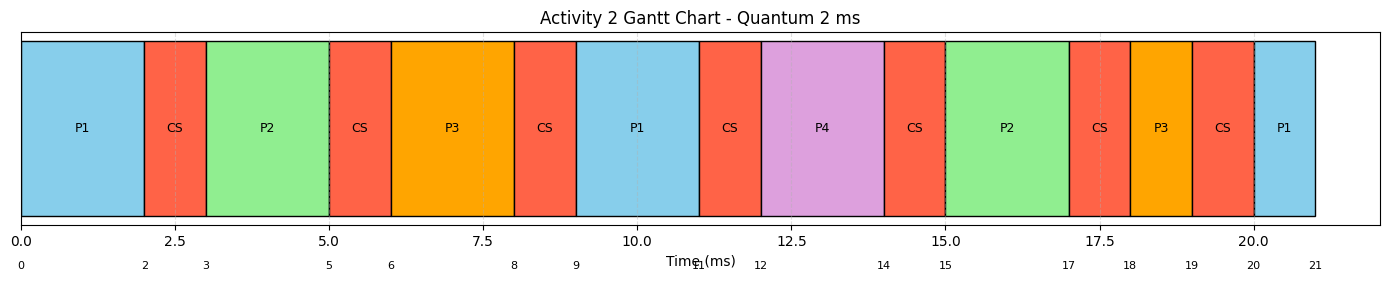


TIME QUANTUM: 4 ms

Execution Schedule:
P1 (0-4) -> CS (4-5) -> P2 (5-9) -> CS (9-10) -> P3 (10-13) -> CS (13-14) -> P4 (14-16) -> CS (16-17) -> P1 (17-18)

Process Performance:
Process  Completion Time  Turnaround Time  Waiting Time  Response Time
     P1               18               18            13              0
     P2                9                8             4              4
     P3               13               11             8              8
     P4               16               13            11             11

Average Turnaround Time: 12.5 ms
Average Waiting Time: 9.0 ms
Average Response Time: 5.75 ms
Context Switches: 4
Total Context Switching Overhead: 4 ms
CPU Efficiency: 77.78 %


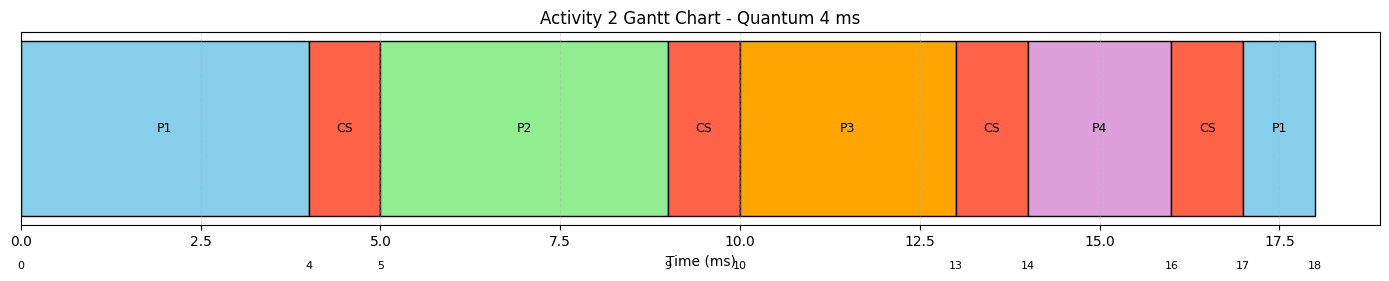


COMPARISON TABLE
 Quantum (ms)  Average Turnaround (ms)  Average Waiting (ms)  Average Response (ms)  Context Switches  Total Overhead (ms)  CPU Efficiency (%)
            2                    16.25                 12.75                   3.75                 7                    7               66.67
            4                    12.50                  9.00                   5.75                 4                    4               77.78


In [3]:

import pandas as pd
import matplotlib.pyplot as plt
from collections import deque

# Activity 2: Climate Emergency Response Centre
processes = [
    {"Process": "P1", "Arrival": 0, "Burst": 5},
    {"Process": "P2", "Arrival": 1, "Burst": 4},
    {"Process": "P3", "Arrival": 2, "Burst": 3},
    {"Process": "P4", "Arrival": 3, "Burst": 2}
]

OVERHEAD = 1  # Context switching overhead in ms


def round_robin(quantum):
    remaining = {p["Process"]: p["Burst"] for p in processes}
    arrival = {p["Process"]: p["Arrival"] for p in processes}
    burst = {p["Process"]: p["Burst"] for p in processes}

    ready = deque()
    schedule = []
    completion = {}
    first_start = {}

    time = 0
    i = 0
    previous = None
    switches = 0

    while len(completion) < len(processes):

        # Add processes that have arrived
        while i < len(processes) and processes[i]["Arrival"] <= time:
            ready.append(processes[i]["Process"])
            i += 1

        # CPU idle time, if needed
        if not ready:
            next_time = processes[i]["Arrival"]
            schedule.append(("IDLE", time, next_time))
            time = next_time
            continue

        current = ready.popleft()

        # Context switch when changing to a different process
        if previous is not None and current != previous:
            schedule.append(("CS", time, time + OVERHEAD))
            time += OVERHEAD
            switches += 1

            # Add processes arriving during the overhead
            while i < len(processes) and processes[i]["Arrival"] <= time:
                ready.append(processes[i]["Process"])
                i += 1

        # Record first CPU start time
        if current not in first_start:
            first_start[current] = time

        # Execute the process
        start = time
        run_time = min(quantum, remaining[current])
        time += run_time
        remaining[current] -= run_time

        schedule.append((current, start, time))

        # Add new arrivals before re-queuing
        while i < len(processes) and processes[i]["Arrival"] <= time:
            ready.append(processes[i]["Process"])
            i += 1

        if remaining[current] > 0:
            ready.append(current)
        else:
            completion[current] = time

        previous = current

    # Calculate performance metrics
    results = []

    for p in processes:
        name = p["Process"]
        turnaround = completion[name] - arrival[name]
        waiting = turnaround - burst[name]
        response = first_start[name] - arrival[name]

        results.append({
            "Process": name,
            "Completion Time": completion[name],
            "Turnaround Time": turnaround,
            "Waiting Time": waiting,
            "Response Time": response
        })

    df = pd.DataFrame(results)

    total_burst = sum(burst.values())
    total_overhead = switches * OVERHEAD

    # Useful CPU time / total elapsed CPU time
    efficiency = (
        total_burst / (total_burst + total_overhead)
    ) * 100

    summary = {
        "Quantum (ms)": quantum,
        "Average Turnaround (ms)": df["Turnaround Time"].mean(),
        "Average Waiting (ms)": df["Waiting Time"].mean(),
        "Average Response (ms)": df["Response Time"].mean(),
        "Context Switches": switches,
        "Total Overhead (ms)": total_overhead,
        "CPU Efficiency (%)": efficiency
    }

    return df, schedule, summary


def draw_gantt(schedule, quantum):
    fig, ax = plt.subplots(figsize=(14, 3))

    colors = {
        "P1": "skyblue",
        "P2": "lightgreen",
        "P3": "orange",
        "P4": "plum",
        "CS": "tomato",
        "IDLE": "lightgray"
    }

    for name, start, end in schedule:
        if end <= start:
            continue

        ax.barh(
            0, end - start, left=start, height=0.5,
            color=colors[name], edgecolor="black"
        )

        ax.text(
            (start + end) / 2, 0, name,
            ha="center", va="center", fontsize=9
        )

        ax.text(start, -0.4, str(start),
                ha="center", fontsize=8)

    if schedule:
        ax.text(schedule[-1][2], -0.4,
                str(schedule[-1][2]),
                ha="center", fontsize=8)

    ax.set_title(
        f"Activity 2 Gantt Chart - Quantum {quantum} ms"
    )
    ax.set_xlabel("Time (ms)")
    ax.set_yticks([])
    ax.set_xlim(left=0)
    ax.grid(axis="x", linestyle="--", alpha=0.4)

    plt.tight_layout()
    plt.show()


# Run both time quantum experiments
summaries = []

for quantum in [2, 4]:
    df, schedule, summary = round_robin(quantum)

    print("\n" + "=" * 50)
    print("TIME QUANTUM:", quantum, "ms")
    print("=" * 50)

    print("\nExecution Schedule:")
    print(" -> ".join(
        f"{name} ({start}-{end})"
        for name, start, end in schedule
    ))

    print("\nProcess Performance:")
    print(df.to_string(index=False))

    print("\nAverage Turnaround Time:",
          round(summary["Average Turnaround (ms)"], 2), "ms")
    print("Average Waiting Time:",
          round(summary["Average Waiting (ms)"], 2), "ms")
    print("Average Response Time:",
          round(summary["Average Response (ms)"], 2), "ms")
    print("Context Switches:", summary["Context Switches"])
    print("Total Context Switching Overhead:",
          summary["Total Overhead (ms)"], "ms")
    print("CPU Efficiency:",
          round(summary["CPU Efficiency (%)"], 2), "%")

    draw_gantt(schedule, quantum)
    summaries.append(summary)

# Comparison table
print("\nCOMPARISON TABLE")
comparison = pd.DataFrame(summaries)
print(comparison.round(2).to_string(index=False))

